In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import matplotlib.ticker as ticker
import matplotlib.patches as patches

In [2]:
from astropy import units, constants
from matplotlib import pyplot as plt, colors
from astropy.cosmology import FlatLambdaCDM, LambdaCDM, Planck13, Planck18

In [3]:
from scipy import stats
from scipy.interpolate import interp1d

In [4]:
from limstat.simulations import cosmological_signal
from limstat.power_spectrum import power_spectrum
from limstat import cosmo_units, plotting
from limstat import fast_interferometer
from limstat import instruments 
from limstat import utils
from limstat.simulations import foregrounds, cosmological_signal

In [5]:
import math

In [6]:
import time

In [7]:
import copy

In [8]:
%load_ext autoreload
%autoreload 2

In [9]:
LUDO_DATA = np.load('./COMAP_DSA_core_EDFN_12h_60s_5km.npy', allow_pickle = True)
data = LUDO_DATA.item()

In [10]:
data

{'g_uu': array([-62.85714286, -60.        , -57.14285714, ...,  57.14285714,
         60.        ,  62.85714286], shape=(213963,)),
 'g_vv': array([-742.85714286, -742.85714286, -742.85714286, ...,  742.85714286,
         742.85714286,  742.85714286], shape=(213963,)),
 'N_uv': array([[307., 292., 332., ..., 332., 292., 307.],
        [311., 304., 303., ..., 303., 304., 311.],
        [304., 309., 312., ..., 312., 309., 304.],
        ...,
        [174., 179., 179., ..., 179., 179., 174.],
        [183., 180., 178., ..., 178., 180., 183.],
        [181., 180., 177., ..., 177., 180., 181.]], shape=(501, 213963)),
 'sefd': <Quantity 0. kJy>,
 'numin_LOFAR': <Quantity 0.16 GHz>,
 'numax_LOFAR': <Quantity 0.21 GHz>,
 'dnu_LOFAR': <Quantity 100. kHz>,
 'k_COMAP': <Quantity [1.04823910e-03, 1.14937132e-03, 1.26026059e-03, 1.38184825e-03,
            1.51516648e-03, 1.66134701e-03, 1.82163077e-03, 1.99737842e-03,
            2.19008189e-03, 2.40137704e-03, 2.63305757e-03, 2.88709021e-03,
    

In [11]:
plt.rcParams['text.usetex'] = False

In [12]:
plt.rcParams['font.family'] = 'DejaVu Sans'

In [13]:
import os, contextlib, io

In [14]:
import h5py

## Angular Size and Frequency Range for Simulation

In [15]:
CO_rest_frequencies = {
    "CO(1-0)": 115.271*units.GHz,
    "CO(2-1)": 230.538*units.GHz,
    "CO(3-2)": 345.796*units.GHz
}

HI_rest_frequency = 1420.4*units.MHz

In [16]:
nu_min_HI = None
nu_max_HI = None

In [17]:
if nu_min_HI == None:
    nu_min_HI = data['numin_LOFAR'].to(units.MHz)
if nu_max_HI == None:
    nu_max_HI = data['numax_LOFAR'].to(units.MHz)

nu_min_HI = max(nu_min_HI.value, HI_rest_frequency.value/(CO_rest_frequencies['CO(2-1)'].value/26))*units.MHz
nu_max_HI = min(nu_max_HI.value, HI_rest_frequency.value/(CO_rest_frequencies['CO(2-1)'].value/34))*units.MHz

nu_max_HI = round(nu_max_HI, 2)
nu_min_HI = round(nu_min_HI, 2)

In [18]:
spw_LOFAR = min(nu_max_HI - nu_min_HI, 8*units.MHz) 
nu_max_HI = nu_min_HI + spw_LOFAR
print(nu_max_HI, nu_min_HI, spw_LOFAR)

168.19 MHz 160.19 MHz 8.0 MHz


In [19]:
band_z_min = (HI_rest_frequency/nu_max_HI).to(units.dimensionless_unscaled).value- 1
band_z_max = (HI_rest_frequency/nu_min_HI).to(units.dimensionless_unscaled).value- 1
print(band_z_min, band_z_max)

7.445210773529936 7.866970472563832


In [20]:
nu_max_CO2_1 = CO_rest_frequencies['CO(2-1)']/(1+band_z_min)
nu_min_CO2_1 = CO_rest_frequencies['CO(2-1)']/(1+band_z_max)

freqs_CO2_1 = np.arange(nu_min_CO2_1.to('GHz').value, 
                     nu_max_CO2_1.to('GHz').value, 
                     data['dnu_COMAP'].to('GHz').value) * units.GHz

spw_COMAP_30GHz = nu_max_CO2_1 - nu_min_CO2_1
print(nu_min_CO2_1, nu_max_CO2_1, spw_COMAP_30GHz)

25.999635468882 GHz 27.29807534497325 GHz 1.2984398760912477 GHz


In [21]:
freqs_HI = np.linspace( nu_min_HI.to(units.MHz).value, 
                        nu_max_HI.to(units.MHz).value,
                        len(freqs_CO2_1)) * units.MHz
z_center = round(float(np.mean(HI_rest_frequency / freqs_HI - 1.0)), 3)
print(f'z_center:{z_center}, dnu:{np.median(np.diff(freqs_HI)).to(units.kHz):.2f}')

z_center:7.653, dnu:98.77 kHz


## UV grids

In [22]:
du = dv = 0.5
u_max = np.abs(data['g_uu']).max() 
v_max = np.abs(data['g_vv']).max() 
u_grid = np.arange(-u_max, u_max + du, du)
v_grid = np.arange(-v_max, v_max + dv, dv)


print(u_grid, v_grid)
# 

[-742.85714286 -742.35714286 -741.85714286 ...  742.14285714  742.64285714
  743.14285714] [-742.85714286 -742.35714286 -741.85714286 ...  742.14285714  742.64285714
  743.14285714]


In [23]:
def _nan_to_zero(arr):
    out = np.asarray(arr, dtype=float)
    return np.nan_to_num(out, nan=0.0, copy=True)

In [24]:
lambda_CO2_1_ref = (constants.c/CO_rest_frequencies['CO(2-1)']*(1+z_center)).to('m')

res_COMAP_30GHz_ref = (lambda_CO2_1_ref/(10.4*units.m))*units.rad

lambda_HI_ref = (constants.c / HI_rest_frequency * (1+z_center)).to(units.m)

#A_eff_tile = (16.0 * lambda_HI_ref**2 / 3.0).to(units.m**2)
A_eff_tile = (lambda_HI_ref**2 / 3.0).to(units.m**2)

Omega_ref = (lambda_HI_ref**2 / A_eff_tile).decompose().value * units.sr

FoV = np.sqrt(Omega_ref.to_value(units.sr)) * units.rad

channel_bandwidth = np.median(np.diff(freqs_HI)).to(units.kHz)

print(f"CO(2-1) Reference wavelength: {lambda_CO2_1_ref:.6g}")
print(f"COMAP resolution at the reference wavelength: {res_COMAP_30GHz_ref.to(units.deg):.6g}")
print(f"HI Reference wavelength: {lambda_HI_ref:.6g}")
print(f"Single-tile A_eff at Band Center: {A_eff_tile:.6g}")
print(f"Omega = lambda^2/A_eff: {Omega_ref:.6g}")
print(f"Square field width: {FoV.to(units.deg):.6g}")
print(f"Simulated channel bandwidth: {channel_bandwidth:.6g}")

CO(2-1) Reference wavelength: 0.0112524 m
COMAP resolution at the reference wavelength: 0.0619918 deg
HI Reference wavelength: 1.82632 m
Single-tile A_eff at Band Center: 1.11181 m2
Omega = lambda^2/A_eff: 3 sr
Square field width: 99.2392 deg
Simulated channel bandwidth: 98.7654 kHz


In [25]:
NPIX_MAX = 402

In [26]:
NPIX_FoV = np.floor((FoV/res_COMAP_30GHz_ref).to(units.dimensionless_unscaled).value).astype(int)
NPIX_box = min(NPIX_FoV, NPIX_MAX)
print(f"Simulation box angular size:", NPIX_box)

Simulation box angular size: 402


In [27]:
cosmo = FlatLambdaCDM( H0=67.81, 
                       Om0=0.3098830430481206, 
                       Ob0=0.048677349798108865, 
                       Tcmb0=2.7255*units.K, 
                       Neff=3.044, 
                       m_nu=[0.  , 0.  , 0.]*units.eV)

In [28]:
cu_simulation_box = cosmo_units.cosmo_units(
    theta_x=res_COMAP_30GHz_ref*NPIX_box, 
    theta_y=res_COMAP_30GHz_ref*NPIX_box, 
    x_npix=NPIX_box,
    y_npix=NPIX_box,
    freqs=freqs_HI,
    cosmo=cosmo
)

## 21cm FG

In [29]:
fg = foregrounds(freqs=freqs_HI,
                 npix=NPIX_box,
                 ang_res=res_COMAP_30GHz_ref.to('arcmin'),
                 RA=269.3*units.deg,
                 Dec=66.0*units.deg,
                 point_sources=True,
                 diffuse=True,
                 beam_area = 1.65e-03 * units.deg**2,
                 use_pygsm=True,
                 pygsm_year = '2016')
fg.use_pygsm = True
pygsm = fg.generate_synchrotron()
FG_21cm_box = pygsm

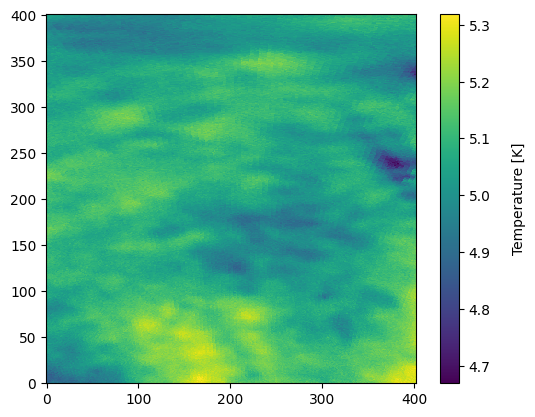

already looking stripey...


In [30]:
# plot slice of FG_21cm_box
plt.imshow(np.log(FG_21cm_box.value[:,:, FG_21cm_box.shape[2]//2]), origin='lower', interpolation='none')
cbar = plt.colorbar()
cbar.set_label('Temperature [K]', rotation=90, labelpad=15)
plt.show()

print('already looking stripey...')

## 21-cm Noise

In [31]:
#SEFD = data['sefd'].to(units.W / (units.m**2 * units.Hz))
#A_eff = A_eff_tile
#Tsys_21cm = (SEFD * A_eff / (2.0 * constants.k_B)).to(units.K)

#print(f"SEFD used: {SEFD.to(units.kJy):.6g}")
#print(f"Single-tile A_eff used: {A_eff:.6g}")

Tsys_21cm = 50 * units.K * (HI_rest_frequency.to(units.MHz).value / (1+z_center) / 150)**(-2.56)

print(f"Corrected Tsys_21cm: {Tsys_21cm:.6g}")

Corrected Tsys_21cm: 39.6953 K


In [32]:
t_obs_noise = (3200/12)*60*units.second

LOFAR = fast_interferometer.fast_interferometer(
    ant_locs= None,
    theta_x=cu_simulation_box.theta_x,
    theta_y=cu_simulation_box.theta_y,
    x_npix=cu_simulation_box.x_npix,
    y_npix=cu_simulation_box.y_npix, 
    T_sys=Tsys_21cm,
    t_obs=t_obs_noise,
    bandwidth=channel_bandwidth,
    # noise_solid_angle=FoV**2, 
)

## old interp N_uv maybe we don't need this anymore... 

In [33]:
data_N_uv_extrpolate = interp1d(
    np.linspace(data['numin_LOFAR'], data['numax_LOFAR'], data['N_uv'].shape[0]),
    data['N_uv'],
    axis=0,
    kind="linear",          
    fill_value="extrapolate"
)

new_data_N_uv_from_extrapolate = data_N_uv_extrpolate(
    freqs_HI.to(units.GHz))

mask_low  = freqs_HI.to(units.GHz) < data['numin_LOFAR']
mask_high = freqs_HI.to(units.GHz) > data['numax_LOFAR']

new_data_N_uv_from_extrapolate[mask_low]  = np.mean(data['N_uv'], axis=0)
new_data_N_uv_from_extrapolate[mask_high] = np.mean(data['N_uv'], axis=0)

np.clip(new_data_N_uv_from_extrapolate, a_min=0, a_max=None, out=new_data_N_uv_from_extrapolate)

array([[304.7       , 308.5       , 311.1       , ..., 311.1       ,
        308.5       , 304.7       ],
       [294.23580247, 318.76419753, 325.31481481, ..., 325.31481481,
        318.76419753, 294.23580247],
       [305.25432099, 307.74567901, 332.25185185, ..., 332.25185185,
        307.74567901, 305.25432099],
       ...,
       [279.07530864, 266.07530864, 269.17160494, ..., 269.17160494,
        266.07530864, 279.07530864],
       [282.64938272, 271.47407407, 275.47407407, ..., 275.47407407,
        271.47407407, 282.64938272],
       [284.8       , 269.3       , 280.5       , ..., 280.5       ,
        269.3       , 284.8       ]], shape=(82, 213963))

In [34]:
N_uv_whole_band_from_extrapolation = []
for jj,nu in enumerate(freqs_HI):
    binned_counts = stats.binned_statistic_2d(
    data['g_uu'],
    data['g_vv'],
    new_data_N_uv_from_extrapolate[jj],
    statistic='sum',
    bins=[u_grid, v_grid],
    )
    N_uv_whole_band_from_extrapolation.append((u_grid, v_grid, _nan_to_zero(binned_counts.statistic)))

In [35]:
np.shape(N_uv_whole_band_from_extrapolation[0][0])

(2973,)

# Test LOFAR N_uv with point source sky

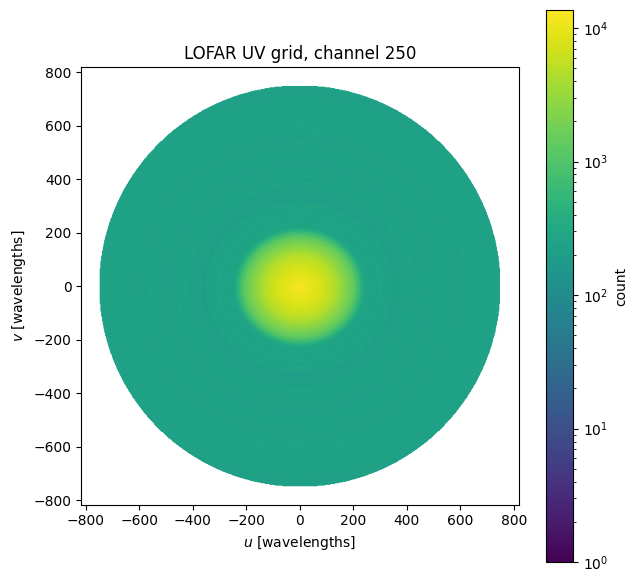

In [36]:
# g_uu and g_vv are one coordinate per UV sample. N_uv is (n_freq, n_uv).
g_uu, g_vv, N_uv = data['g_uu'], data['g_vv'], data['N_uv']
ichan = N_uv.shape[0] // 2
counts = N_uv[ichan]

fig, ax = plt.subplots(figsize=(6.5, 6))
sc = ax.scatter(
    g_uu,
    g_vv,
    c=counts,
    s=1,
    cmap='viridis',
    norm=colors.LogNorm(vmin=1, vmax=counts.max()),
    rasterized=True,
)
ax.set_aspect('equal')
ax.set_xlabel(r'$u$ [wavelengths]')
ax.set_ylabel(r'$v$ [wavelengths]')
ax.set_title(f'LOFAR UV grid, channel {ichan}')
fig.colorbar(sc, ax=ax, label='count')
fig.tight_layout()

u (521,), v (521,), count_map (521, 521)
du = 2.85714, dv = 2.85714
input sum 1.17497e+08, image sum 1.17497e+08


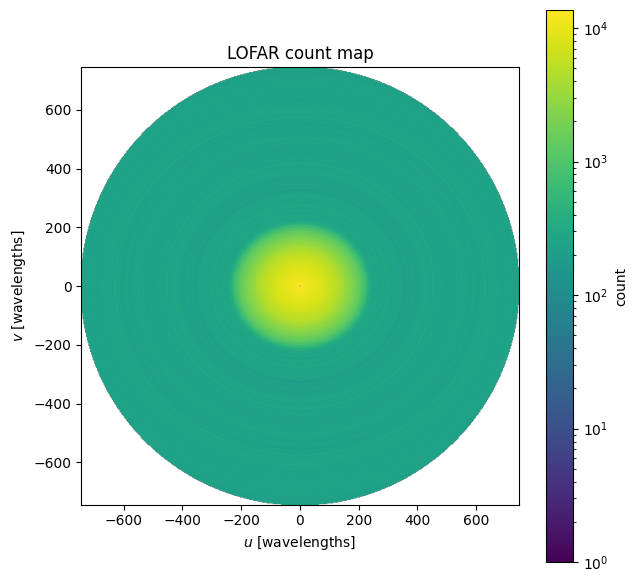

In [37]:
# Place one frequency channel onto the regular lattice.
# u_cent and v_cent have the same length as count_map, so they are cell centres.
g_uu, g_vv = data['g_uu'], data['g_vv']
counts = data['N_uv'][data['N_uv'].shape[0] // 2]

u_cent = np.unique(g_uu)
v_cent = np.unique(g_vv)
du = np.median(np.diff(u_cent))
dv = np.median(np.diff(v_cent))
iu = np.rint((g_uu - u_cent[0]) / du).astype(int)
iv = np.rint((g_vv - v_cent[0]) / dv).astype(int)

count_map = np.zeros((len(v_cent), len(u_cent)))
np.add.at(count_map, (iv, iu), counts)
N_uv_lofar = (u_cent, v_cent, count_map)

print(f'u {u_cent.shape}, v {v_cent.shape}, count_map {count_map.shape}')
print(f'du = {du:.6g}, dv = {dv:.6g}')
print(f'input sum {counts.sum():.6g}, image sum {count_map.sum():.6g}')

fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(
    count_map,
    origin='lower',
    cmap='viridis',
    norm=colors.LogNorm(vmin=1, vmax=count_map.max()),
    extent=[
        u_cent[0] - du / 2, u_cent[-1] + du / 2,
        v_cent[0] - dv / 2, v_cent[-1] + dv / 2,
    ],
)
ax.set_aspect('equal')
ax.set_xlabel(r'$u$ [wavelengths]')
ax.set_ylabel(r'$v$ [wavelengths]')
ax.set_title('LOFAR count map')
fig.colorbar(im, ax=ax, label='count')
fig.tight_layout()


In [38]:
# make a gaussian point source sky 
yy, xx = np.mgrid[0:NPIX_box, 0:NPIX_box]
cy, cx = NPIX_box // 2, NPIX_box // 2
sigma = 4.0
sky = np.exp(-((xx - cx + 10) ** 2 + (yy - cy - 6) ** 2) / (2 * sigma ** 2))



UV plane 402 x 402 (du=2.37325, dv=2.37325, 2.6 MB complex)
UV plane 402 x 402 (du=2.37325, dv=2.37325, 2.6 MB complex)


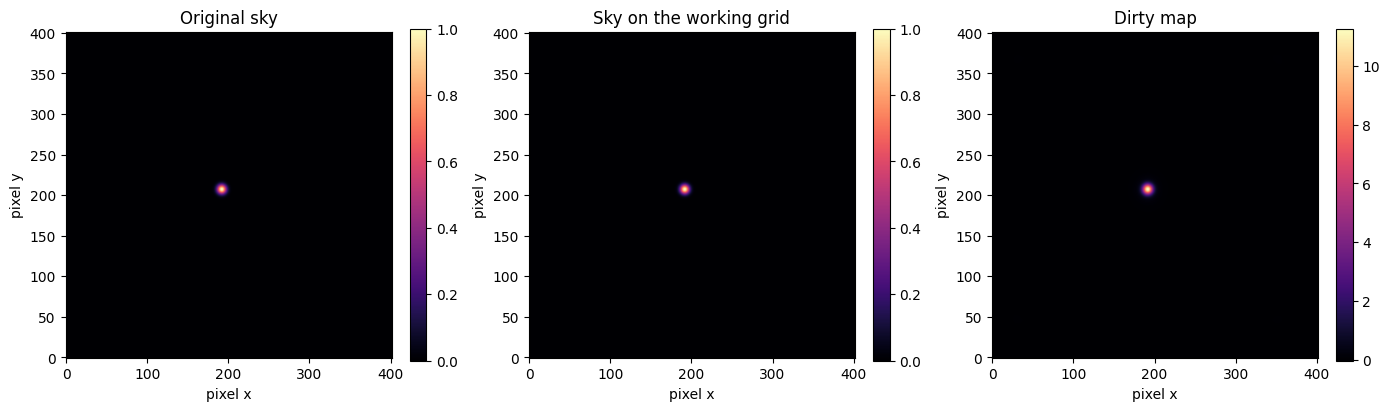

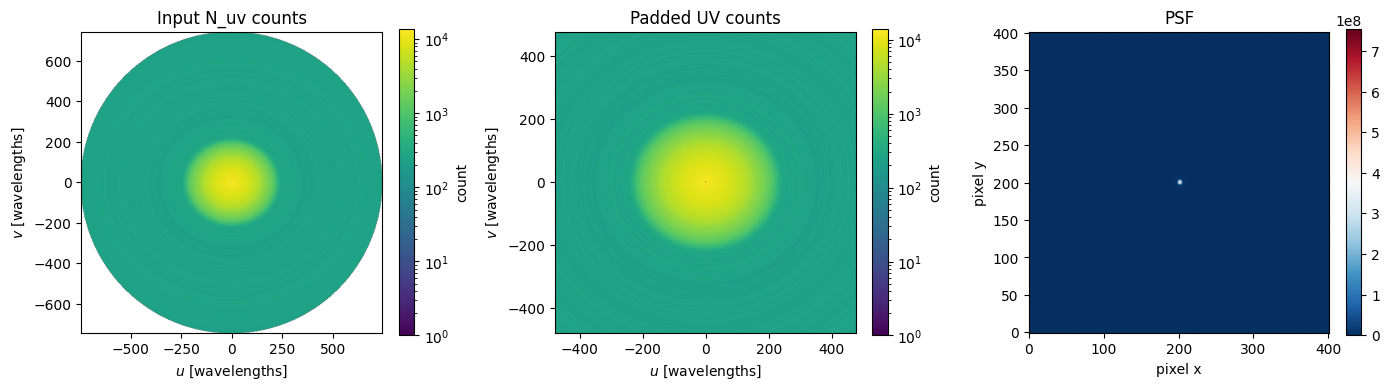

In [42]:
freq = np.linspace(
    data['numin_LOFAR'].to(units.MHz).value,
    data['numax_LOFAR'].to(units.MHz).value,
    data['N_uv'].shape[0],
)[data['N_uv'].shape[0] // 2] * units.MHz

dirty = LOFAR.get_dirty_map(sky, freq, N_uv=N_uv_lofar, noise=False)
working_sky = LOFAR._pad_sky(sky)
psf = LOFAR.get_psf(freq, N_uv=N_uv_lofar)
uv_padded = LOFAR.count_map
input_counts = N_uv_lofar[2]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, image, title, cmap in (
    (axes[0], sky, 'Original sky', 'magma'),
    (axes[1], working_sky, 'Sky on the working grid', 'magma'),
    (axes[2], dirty, 'Dirty map', 'magma'),
):
    im = ax.imshow(image, origin='lower', cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel('pixel x')
    ax.set_ylabel('pixel y')
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
u_cent, v_cent = N_uv_lofar[0], N_uv_lofar[1]
du = np.median(np.diff(u_cent))
dv = np.median(np.diff(v_cent))

im0 = axes[0].imshow(
    input_counts,
    origin='lower',
    cmap='viridis',
    norm=colors.LogNorm(vmin=1, vmax=input_counts.max()),
    extent=[
        u_cent[0] - du / 2, u_cent[-1] + du / 2,
        v_cent[0] - dv / 2, v_cent[-1] + dv / 2,
    ],
)
axes[0].set_aspect('equal')
axes[0].set_title('Input N_uv counts')
axes[0].set_xlabel(r'$u$ [wavelengths]')
axes[0].set_ylabel(r'$v$ [wavelengths]')
fig.colorbar(im0, ax=axes[0], fraction=0.046, label='count')

im1 = axes[1].imshow(
    uv_padded,
    origin='lower',
    cmap='viridis',
    norm=colors.LogNorm(vmin=1, vmax=max(uv_padded.max(), 1)),
    extent=[
        LOFAR.u_grid[0], LOFAR.u_grid[-1],
        LOFAR.v_grid[0], LOFAR.v_grid[-1],
    ],
)
axes[1].set_aspect('equal')
axes[1].set_title('Padded UV counts')
axes[1].set_xlabel(r'$u$ [wavelengths]')
axes[1].set_ylabel(r'$v$ [wavelengths]')
fig.colorbar(im1, ax=axes[1], fraction=0.046, label='count')

im2 = axes[2].imshow(psf, origin='lower', cmap='RdBu_r')
axes[2].set_title('PSF')
axes[2].set_xlabel('pixel x')
axes[2].set_ylabel('pixel y')
fig.colorbar(im2, ax=axes[2], fraction=0.046)
fig.tight_layout()


In [43]:
u_sky, v_sky,_,_,_,_ = LOFAR.sky_uv_coords()
du_sky=np.median(np.diff(u_sky))
dv_sky = np.median(np.diff(v_sky))

print(du_sky, dv_sky)

u_lofar = N_uv_lofar[0]
v_lofar =N_uv_lofar[1]
du_lofar=np.median(np.diff(u_lofar))
dv_lofar = np.median(np.diff(v_lofar))

print (du_lofar, dv_lofar)

# du_sky < du_lofar this means that the sky extent in position space is larger 
# the extent of the fourier transform of the uv map on the native lofar grid 
# in this case if du_sky < du_lofar, then we want to pad the uv_map in position space with zeros

 


2.3732479103876187 2.3732479103876187
2.8571428571428896 2.8571428571428896


## LOFAR on diffuse sky

UV plane 402 x 402 (du=2.37325, dv=2.37325, 2.6 MB complex)
UV plane 402 x 402 (du=2.37325, dv=2.37325, 2.6 MB complex)
FG channel 41, frequency 164.2 MHz
working grid (402, 402), du=2.373, dv=2.373, |u| <= 475.8, |v| <= 475.8


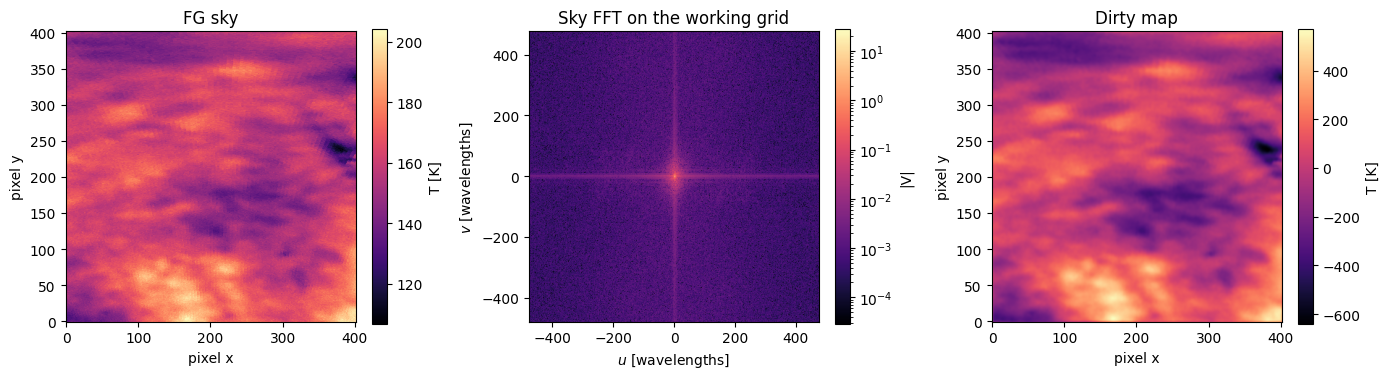

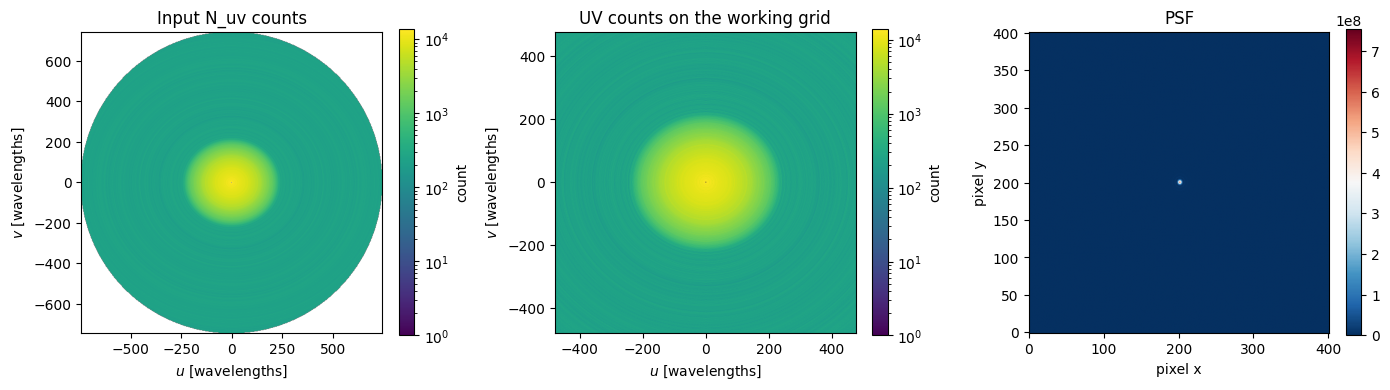

In [44]:
ichan = FG_21cm_box.shape[2] // 2
fg_sky = np.asarray(FG_21cm_box.value[:, :, ichan], dtype=float)
freq_fg = freqs_HI[ichan]

dirty_fg = LOFAR.get_dirty_map(fg_sky, freq_fg, N_uv=N_uv_lofar, noise=False)
psf_fg = LOFAR.get_psf(freq_fg, N_uv=N_uv_lofar)
_, _, _, _, dl, dm = LOFAR.sky_uv_coords()
sky_on_grid = LOFAR._pad_sky(fg_sky)
sky_fft = (
    np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(sky_on_grid)))
    * (dl * dm)
)
uv_counts = LOFAR.count_map
input_counts = N_uv_lofar[2]
u_edge, v_edge = LOFAR.u_grid, LOFAR.v_grid
print(f'FG channel {ichan}, frequency {freq_fg:.4g}')
print(
    f'working grid {uv_counts.shape}, du={LOFAR.du:.4g}, dv={LOFAR.dv:.4g}, '
    f'|u| <= {u_edge[-1]:.4g}, |v| <= {v_edge[-1]:.4g}'
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
im = axes[0].imshow(fg_sky, origin='lower', cmap='magma')
axes[0].set_title('FG sky')
axes[0].set_xlabel('pixel x')
axes[0].set_ylabel('pixel y')
fig.colorbar(im, ax=axes[0], fraction=0.046, label='T [K]')

amp = np.abs(sky_fft)
im = axes[1].imshow(
    amp,
    origin='lower',
    cmap='magma',
    norm=colors.LogNorm(vmin=max(amp.max() * 1e-6, 1e-30), vmax=amp.max()),
    extent=[u_edge[0], u_edge[-1], v_edge[0], v_edge[-1]],
)
axes[1].set_aspect('equal')
axes[1].set_title('Sky FFT on the working grid')
axes[1].set_xlabel(r'$u$ [wavelengths]')
axes[1].set_ylabel(r'$v$ [wavelengths]')
fig.colorbar(im, ax=axes[1], fraction=0.046, label='|V|')

im = axes[2].imshow(dirty_fg, origin='lower', cmap='magma')
axes[2].set_title('Dirty map')
axes[2].set_xlabel('pixel x')
axes[2].set_ylabel('pixel y')
fig.colorbar(im, ax=axes[2], fraction=0.046, label='T [K]')
fig.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
u_cent, v_cent = N_uv_lofar[0], N_uv_lofar[1]
du = np.median(np.diff(u_cent))
dv = np.median(np.diff(v_cent))

im0 = axes[0].imshow(
    input_counts,
    origin='lower',
    cmap='viridis',
    norm=colors.LogNorm(vmin=1, vmax=input_counts.max()),
    extent=[
        u_cent[0] - du / 2, u_cent[-1] + du / 2,
        v_cent[0] - dv / 2, v_cent[-1] + dv / 2,
    ],
)
axes[0].set_aspect('equal')
axes[0].set_title('Input N_uv counts')
axes[0].set_xlabel(r'$u$ [wavelengths]')
axes[0].set_ylabel(r'$v$ [wavelengths]')
fig.colorbar(im0, ax=axes[0], fraction=0.046, label='count')

im1 = axes[1].imshow(
    uv_counts,
    origin='lower',
    cmap='viridis',
    norm=colors.LogNorm(vmin=1, vmax=max(uv_counts.max(), 1)),
    extent=[u_edge[0], u_edge[-1], v_edge[0], v_edge[-1]],
)
axes[1].set_aspect('equal')
axes[1].set_title('UV counts on the working grid')
axes[1].set_xlabel(r'$u$ [wavelengths]')
axes[1].set_ylabel(r'$v$ [wavelengths]')
fig.colorbar(im1, ax=axes[1], fraction=0.046, label='count')

im2 = axes[2].imshow(psf_fg, origin='lower', cmap='RdBu_r')
axes[2].set_title('PSF')
axes[2].set_xlabel('pixel x')
axes[2].set_ylabel('pixel y')
fig.colorbar(im2, ax=axes[2], fraction=0.046)
fig.tight_layout()

# Add noise